[Анализ обогащения GO Biological Process](https://geneontology.org/docs/go-enrichment-analysis/) показывает, гены каких процессов встречаются среди значимых генов чаще, чем ожидается по фоновому набору. Отдельно рассмотрим гены с повышенной и пониженной экспрессией (`padj < 0.05`). Фон составят гены из `res` с рассчитанным `padj`, найденные в справочнике GO. Обогащение рассчитаем как отношение наблюдаемого числа генов процесса к ожидаемому. Его статистическую значимость оценим гипергеометрическим тестом, а полученные p-value скорректируем методом Бенджамини–Хохберга.

**Аннотация GO Biological Process.** Используем файл `hsapiens.GO:BP.ENSG.gmt` с сайта [g:Profiler](https://biit.cs.ut.ee/gprofiler/gost). В каждой строке записаны ID и название процесса, а также Ensembl ID связанных с ним генов.

Сначала получим общий обзор обогащённых процессов, затем подробнее рассмотрим иммунные процессы и участвующие в них гены.

### Подготовка данных

In [44]:
# готовим списки генов из результатов DESeq2 (res)

# оставляем строки, где DESeq2 рассчитал padj
res_tested <- subset(as.data.frame(res), !is.na(padj))

# берём ID всех генов из этих строк
res_background <- rownames(res_tested)

# из того же набора выбираем значимые гены по направлению эффекта
res_up <- rownames(subset(res_tested, padj < 0.05 & log2FoldChange > 0))
res_down <- rownames(subset(res_tested, padj < 0.05 & log2FoldChange < 0))

# проверяем, сколько генов в каждом списке
c(background = length(res_background),
  up = length(res_up),
  down = length(res_down))

background         up       down 
     16997       2170       2254

In [45]:
# готовим аннотацию

# читаем строки GMT и делим каждую по табуляции
gmt_lines <- readLines("data/reference/hsapiens.GO:BP.ENSG.gmt")
gmt_rows <- strsplit(gmt_lines, "\t", fixed = TRUE)

# для каждого процесса оставляем только ID генов
gmt_gene_sets <- lapply(gmt_rows, function(row) row[-c(1, 2)])

# собираем все ID генов в единый список и убираем повторы
gmt_gene_ids <- unique(unlist(gmt_gene_sets))


In [46]:
# проверяем, сколько генов из списков res есть в GMT
c(
  background = sum(sub("\\.[0-9]+$", "", res_background) %in% gmt_gene_ids),
  up = sum(sub("\\.[0-9]+$", "", res_up) %in% gmt_gene_ids),
  down = sum(sub("\\.[0-9]+$", "", res_down) %in% gmt_gene_ids)
)

background         up       down 
     12956       1864       1802

In [47]:
# готовим данные для расчета

# фон: гены из результатов, которые есть в GMT
annotated_background <- intersect(
  sub("\\.[0-9]+$", "", res_background),
  gmt_gene_ids
)

# гены с повышением, входящие в этот фон
annotated_up <- intersect(
  sub("\\.[0-9]+$", "", res_up),
  annotated_background
)

# гены с понижением, входящие в этот фон
annotated_down <- intersect(
  sub("\\.[0-9]+$", "", res_down),
  annotated_background
)


In [48]:
# cоздаём таблицу процессов: одна строка – один процесс
go_terms <- data.frame(
  term_id = vapply(gmt_rows, function(row) row[1], character(1)),
  term_name = vapply(gmt_rows, function(row) row[2], character(1))
)

# добавляем для каждого процесса список его генов из нашего фона
go_terms$gene_ids <- lapply(
  gmt_gene_sets, intersect, y = annotated_background
)

# добавление количество генов в каждом списке
go_terms$term_size <- lengths(go_terms$gene_ids)

# оставляем процессы, у которых есть хотя бы один ген в фоне
go_terms <- subset(go_terms, term_size > 0)

# смотрим первые пять строк
head(go_terms, 5)

,term_id,term_name,gene_ids,term_size
,<chr>,<chr>,<list>,<int>
1,GO:0000012,single strand break repair,ENSG0000....,14
3,GO:0000018,regulation of DNA recombination,ENSG0000....,127
4,GO:0000019,regulation of mitotic recombination,ENSG0000....,5
5,GO:0000022,mitotic spindle elongation,ENSG0000....,10
6,GO:0000023,maltose metabolic process,ENSG0000....,1


### Расчет обогащения

Ищем **процессы с избыточной представленностью генов**: в списке up или down генов данного процесса значимо больше, чем ожидалось при случайном выборе из фона списка того же размера.

Гипергеометрическим тестом проверяем только избыток (`lower.tail = FALSE`), затем оставляем процессы с `padj < 0.05`. Отбор относится к **процессам**, а не к отдельным генам. Проверку выполняем отдельно для up и down; недостаточную представленность здесь не исследуем.


#### Гены с повышением экспрессии

In [49]:
# создаём таблицу процессов с генами повышения
go_up_result <- go_terms
go_up_result$observed <- lengths(
  lapply(go_up_result$gene_ids, intersect, y = annotated_up)
)

head(go_up_result[, c("term_name", "term_size", "observed")], 5)

,term_name,term_size,observed
,<chr>,<int>,<int>
1,single strand break repair,14,4
3,regulation of DNA recombination,127,43
4,regulation of mitotic recombination,5,0
5,mitotic spindle elongation,10,8
6,maltose metabolic process,1,0


In [50]:
# рассчитываем ожидаемое количество генов каждого процесса
go_up_result$expected <- length(annotated_up) *
  go_up_result$term_size / length(annotated_background)

# добавляем величину обогащения для каждого процесса
go_up_result$enrichment <- go_up_result$observed / go_up_result$expected

head(go_up_result[, c("term_name", "observed", "expected", "enrichment")], 5)

,term_name,observed,expected,enrichment
,<chr>,<int>,<dbl>,<dbl>
1,single strand break repair,4,2.0142019,1.985898
3,regulation of DNA recombination,43,18.2716888,2.353368
4,regulation of mitotic recombination,0,0.7193578,0.000000
5,mitotic spindle elongation,8,1.4387157,5.560515
6,maltose metabolic process,0,0.1438716,0.000000


In [51]:
# p-value: вероятность случайно получить столько же или больше генов процесса
go_up_result$pvalue <- phyper(
  q = go_up_result$observed - 1,
  m = go_up_result$term_size,           # гены процесса в фоне
  n = length(annotated_background) - go_up_result$term_size,     # остальные гены фона
  k = length(annotated_up),             # размер списка повышенных генов
  lower.tail = FALSE  # проверяем только избыток генов относительно ожидаемого
)

# корректируем p-value методом Бенджамини–Хохберга
go_up_result$padj <- p.adjust(go_up_result$pvalue, method = "BH")

# сортируем всю таблицу по возрастанию padj
go_up_result <- go_up_result[order(go_up_result$padj), ]

# смотрим первые пять процессов
head(go_up_result[, c("term_name", "observed", "expected", "enrichment", "padj")], 5)

,term_name,observed,expected,enrichment,padj
,<chr>,<int>,<dbl>,<dbl>,<dbl>
8004,chromosome organization,196,73.94998,2.650440,3.835177e-38
1349,DNA metabolic process,275,128.62118,2.138062,4.073941e-35
3886,cell cycle process,306,159.55357,1.917851,8.994257e-30
1837,chromosome segregation,146,54.67119,2.670511,2.091821e-28
51,nuclear division,139,51.21828,2.713875,7.343976e-28


In [52]:
# оставляем процессы, в которых генов из списка up значимо больше ожидаемого по фону
go_up_sig <- subset(go_up_result, padj < 0.05)

# проверяем их количество
nrow(go_up_sig)

head(go_up_sig[, c("term_id", "term_name", "observed", "expected", "enrichment", "padj")], 5)

[1] 399

,term_id,term_name,observed,expected,enrichment,padj
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
8004,GO:0051276,chromosome organization,196,73.94998,2.650440,3.835177e-38
1349,GO:0006259,DNA metabolic process,275,128.62118,2.138062,4.073941e-35
3886,GO:0022402,cell cycle process,306,159.55357,1.917851,8.994257e-30
1837,GO:0007059,chromosome segregation,146,54.67119,2.670511,2.091821e-28
51,GO:0000280,nuclear division,139,51.21828,2.713875,7.343976e-28


#### Гены с понижением экспрессии

In [53]:
# таблица процессов с генами понижения
go_down_result <- go_terms
go_down_result$observed <- lengths(
  lapply(go_down_result$gene_ids, intersect, y = annotated_down)
)

# ожидаемое количество генов каждого процесса
go_down_result$expected <- length(annotated_down) *
  go_down_result$term_size / length(annotated_background)

# величина обогащения: наблюдаемое количество / ожидаемое
go_down_result$enrichment <- go_down_result$observed /
  go_down_result$expected

# p-value: вероятность получить столько же или больше совпадений при случайном выборе генов из фона
go_down_result$pvalue <- phyper(
  q = go_down_result$observed - 1,
  m = go_down_result$term_size,  
  n = length(annotated_background) - go_down_result$term_size,  
  k = length(annotated_down),  
  lower.tail = FALSE  # проверяем только избыток генов относительно ожидаемого
)

# корректируем p-value методом Бенджамини–Хохберга
go_down_result$padj <- p.adjust(
  go_down_result$pvalue,
  method = "BH"
)

# сортируем всю таблицу по возрастанию padj
go_down_result <- go_down_result[order(go_down_result$padj), ]

# оставляем процессы, в которых генов из списка down значимо больше ожидаемого по фону
go_down_sig <- subset(go_down_result, padj < 0.05)

# проверяем их количество
nrow(go_down_sig)

head(go_down_sig[, c("term_id", "term_name", "observed", "expected", "enrichment", "padj")], 5)

[1] 95

,term_id,term_name,observed,expected,enrichment,padj
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
974,GO:0003008,system process,278,171.07595,1.625009,3.193993e-14
978,GO:0003012,muscle system process,88,42.69944,2.060917,3.930091e-08
1769,GO:0006936,muscle contraction,72,32.12890,2.240973,3.930091e-08
7493,GO:0048513,animal organ development,399,306.96311,1.299830,3.240838e-06
979,GO:0003013,circulatory system process,103,59.80704,1.722205,2.075218e-05


### Обзор процессов с избыточной представленностью генов

In [67]:
# можем найти один процесс или интересующую тему
subset(
  go_up_sig,
  term_id == "GO:0032963",
  # grepl("collagen", term_name, ignore.case = TRUE),
  select = c(term_name, observed, expected, enrichment, padj)
)

,term_name,observed,expected,enrichment,padj
,<chr>,<int>,<dbl>,<dbl>,<dbl>
4803,collagen metabolic process,28,12.37295,2.263,0.0009837054


In [68]:
# основные биологические темы для обзорного графика
summary_ids <- c(
  "GO:0022402",  # процессы клеточного цикла

  "GO:0006260",  # репликация ДНК
  "GO:0006281",  # восстановление ДНК
  "GO:0006396",  # обработка РНК

  "GO:0002250",  # адаптивный иммунный ответ
  "GO:0045087",  # врождённый иммунный ответ

  "GO:0032963",  # обмен коллагена

  "GO:0006936",  # мышечное сокращение
  "GO:0008015",  # кровообращение
  "GO:0050877",  # процессы нервной системы
  "GO:0006631"   # обмен жирных кислот
)


# объединяем значимые результаты двух направлений,
go_summary <- rbind(
  transform(go_up_sig, direction = "Повышенные"),
  transform(go_down_sig, direction = "Пониженные")
)

# оставляем выбранные процессы и нужные для обзора столбцы
go_summary <- subset(
  go_summary,
  term_id %in% summary_ids,
  select = c(direction, term_id, term_name, observed, expected, enrichment, padj)
)

go_summary

,direction,term_id,term_name,observed,expected,enrichment,padj
,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
3886,Повышенные,GO:0022402,cell cycle process,306,159.55357,1.917851,8.994257e-30
1362,Повышенные,GO:0006281,DNA repair,181,82.58228,2.191754,7.473372e-24
1350,Повышенные,GO:0006260,DNA replication,112,40.57178,2.760539,3.708645e-23
1417,Повышенные,GO:0006396,RNA processing,225,146.60513,1.534735,5.800854e-10
536,Повышенные,GO:0002250,adaptive immune response,106,59.56283,1.779633,9.934427e-08
4803,Повышенные,GO:0032963,collagen metabolic process,28,12.37295,2.263000,9.837054e-04
6641,Повышенные,GO:0045087,innate immune response,139,107.47206,1.293359,2.396117e-02
1769,Пониженные,GO:0006936,muscle contraction,72,32.12890,2.240973,3.930091e-08
2082,Пониженные,GO:0008015,blood circulation,90,50.48827,1.782592,2.250890e-05


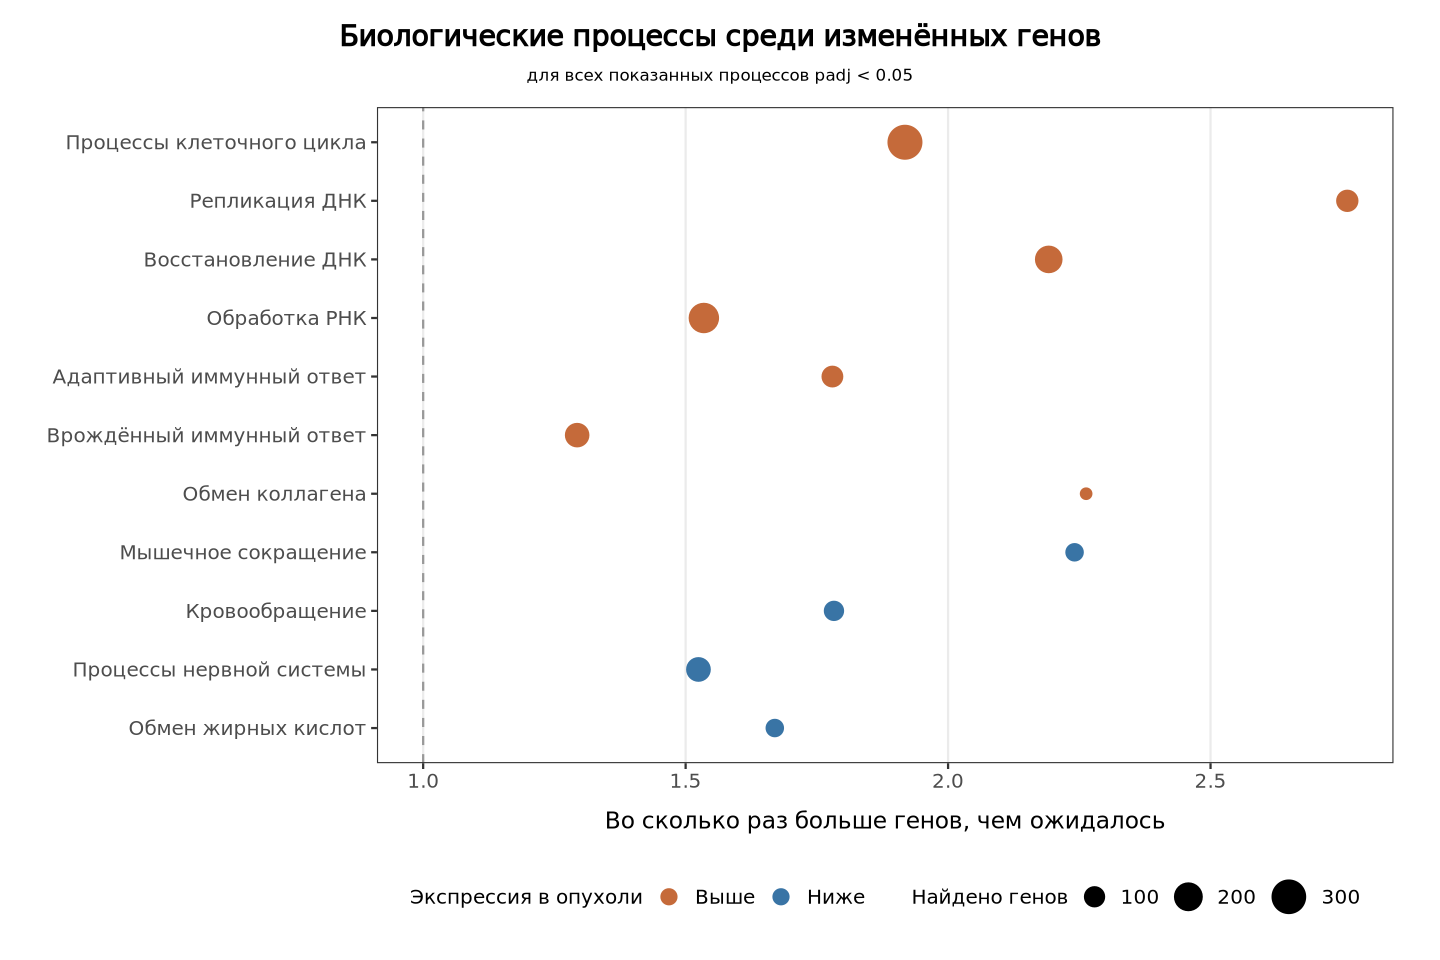

In [69]:
library(ggplot2)

# подписи процессов на русском
summary_labels <- c(
  "GO:0022402" = "Процессы клеточного цикла",
  "GO:0006260" = "Репликация ДНК",
  "GO:0006281" = "Восстановление ДНК",
  "GO:0006396" = "Обработка РНК",
  "GO:0002250" = "Адаптивный иммунный ответ",
  "GO:0045087" = "Врождённый иммунный ответ",
  "GO:0032963" = "Обмен коллагена",
  "GO:0006936" = "Мышечное сокращение",
  "GO:0008015" = "Кровообращение",
  "GO:0050877" = "Процессы нервной системы",
  "GO:0006631" = "Обмен жирных кислот"
)

# сохраняем смысловой порядок процессов сверху вниз
go_summary$term_id <- factor(go_summary$term_id, levels = rev(summary_ids))

# X — обогащение, Y — процесс, размер точки — число генов, цвет — направление
go_plot <- ggplot(go_summary, aes(x = enrichment, y = term_id, colour = direction)) +
  geom_vline(xintercept = 1, linetype = "dashed", colour = "grey60") +
  geom_point(aes(size = observed)) +
  scale_size_area(name = "Найдено генов", max_size = 9) +
  scale_colour_manual(
    name = "Экспрессия в опухоли",
    values = c("Повышенные" = "#C56A3A", "Пониженные" = "#3974A5"),
    breaks = c("Повышенные", "Пониженные"),
    labels = c("Выше", "Ниже")
  ) +
  scale_y_discrete(labels = summary_labels) +
  labs(
    title = "Биологические процессы среди изменённых генов",
    subtitle = "для всех показанных процессов padj < 0.05",
    x = "Во сколько раз больше генов, чем ожидалось",
    y = NULL
  ) +
  # две легенды в одну строку
  guides(
    colour = guide_legend(order = 1, nrow = 1, override.aes = list(size = 4)),
    size = guide_legend(order = 2, nrow = 1)
  ) +
  theme_bw(base_size = 14) +
  theme(
    axis.text = element_text(size = 12),
    axis.title.x = element_text(margin = margin(t = 12)), # Отступ подписи от оси
    plot.title.position = "plot",
    plot.title = element_text(size = 17, face = "bold", hjust = 0.5,
                              margin = margin(b = 10)),
    plot.subtitle = element_text(size = 10, hjust = 0.5, margin = margin(b = 14)),
    legend.position = "bottom",
    legend.box = "horizontal",
    legend.box.just = "center",
    legend.key.height = grid::unit(12, "mm"), # Одна высота для обеих легенд
    legend.title = element_text(size = 12),
    legend.text = element_text(size = 12),
    panel.grid.major.y = element_blank(),
    panel.grid.minor = element_blank(),
    plot.margin = margin(t = 14, r = 28, b = 14, l = 28)
  )

# PNG нужен для корректных русских подписей; файл временный
plot_png <- tempfile(fileext = ".png")
png(plot_png, width = 12, height = 8, units = "in", res = 120, type = "cairo")
print(go_plot)
invisible(dev.off())
IRdisplay::display_png(file = plot_png, width = 864, height = 576)


### Иммунные процессы: основные темы

Просмотрели значимые процессы в `go_up_sig` и `go_down_sig` и вручную составили рабочий список GO ID, связанных с иммунитетом. Искали не только слово `immune`: учли также интерфероны, цитокины, антитела, иммунные клетки и презентацию антигенов. Это тематический отбор для текущего анализа; полный обход всех связей GO здесь не выполняем.

| Тема | Какие процессы объединяем |
| --- | --- |
| Общие иммунные процессы | Иммунный ответ в целом, развитие иммунной системы, работа лейкоцитов. |
| Адаптивный ответ и антитела | Адаптивный ответ, образование антител и разнообразие иммунных рецепторов. |
| Активация иммунных клеток | Активация лейкоцитов, лимфоцитов, T- и B-клеток. |
| Врождённый ответ и защита от возбудителей | Врождённый ответ, защита слизистых, ответы на вирусы и бактерии. |
| Интерфероны | Сигналы интерферонов I типа и образование интерферона II типа. |
| Цитокины и воспаление | Образование цитокинов (в том числе TNF, IL-1 и IL-2), их регуляция и пироптотический воспалительный ответ. |
| Презентация антигенов | Обработка и представление антигенов, в частности через MHC I. |

Каждому термину назначаем одну основную тему для удобства просмотра. Темы биологически пересекаются: например, интерфероны относятся к цитокинам. Общие и более узкие термины GO могут содержать одни и те же гены, поэтому число терминов не равно числу независимых находок, а количества генов по строкам не складываем. Подробнее: [связи между терминами GO](https://geneontology.org/docs/ontology-relations/).

Используем уже рассчитанные `padj`; группировка не является новым статистическим тестом. В таблице ниже считаем **термины**, отдельно для up и down. Ноль в down означает отсутствие значимых терминов из нашего рабочего списка в этой группе, а не отсутствие отдельных иммунных генов с пониженной экспрессией.


In [72]:
# рабочий набор из 69 иммунных GO-терминов, выбранных вручную
immune_ids <- c(
  "GO:0001816", "GO:0001817", "GO:0001819", "GO:0002200",
  "GO:0002204", "GO:0002208", "GO:0002227", "GO:0002250",
  "GO:0002252", "GO:0002376", "GO:0002377", "GO:0002428",
  "GO:0002440", "GO:0002443", "GO:0002449", "GO:0002460",
  "GO:0002474", "GO:0002476", "GO:0002483", "GO:0002484",
  "GO:0002486", "GO:0002520", "GO:0002562", "GO:0002819",
  "GO:0002821", "GO:0002822", "GO:0002824", "GO:0006955",
  "GO:0009615", "GO:0016064", "GO:0016445", "GO:0016447",
  "GO:0019724", "GO:0019885", "GO:0032609", "GO:0032611",
  "GO:0032612", "GO:0032623", "GO:0032640", "GO:0032649",
  "GO:0032651", "GO:0032652", "GO:0032663", "GO:0032680",
  "GO:0032714", "GO:0032720", "GO:0032729", "GO:0034340",
  "GO:0042110", "GO:0042113", "GO:0042742", "GO:0045087",
  "GO:0045190", "GO:0045321", "GO:0045824", "GO:0046649",
  "GO:0048002", "GO:0050830", "GO:0051607", "GO:0060337",
  "GO:0060338", "GO:0070269", "GO:0071357", "GO:0071706",
  "GO:0098542", "GO:0140546", "GO:0140888", "GO:1903555",
  "GO:1903556"
)

# объединяем строки в таблицу и добавляем направление
immune_results <- rbind(
  transform(go_up_result, direction = "up"),
  transform(go_down_result, direction = "down")
)

# оставляем процессы из нашего набора с padj < 0.05
immune_results <- subset(
  immune_results,
  term_id %in% immune_ids & padj < 0.05,
  select = c(
    term_id, term_name, direction,
    observed, expected, enrichment, padj
  )
)

# сортируем по убыванию представленности и меньшему padj, 
immune_results <- immune_results[
  order(-immune_results$enrichment, immune_results$padj),
]

# берем топ 15
immune_top <- head(immune_results, 15)
immune_top

,term_id,term_name,direction,observed,expected,enrichment,padj
,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
4667,GO:0032714,negative regulation of interleukin-5 production,up,4,0.5754863,6.950644,0.0175831089
526,GO:0002227,innate immune response in mucosa,up,8,1.7264588,4.633763,0.0028953867
683,GO:0002476,antigen processing and presentation of endogenous peptide antigen via MHC class Ib,up,7,1.5825872,4.423137,0.0111555072
690,GO:0002484,antigen processing and presentation of endogenous peptide antigen via MHC class I via ER pathway,up,7,1.5825872,4.423137,0.0111555072
692,GO:0002486,"antigen processing and presentation of endogenous peptide antigen via MHC class I via ER pathway, TAP-independent",up,6,1.4387157,4.170386,0.0385769543
646,GO:0002428,antigen processing and presentation of peptide antigen via MHC class Ib,up,7,1.7264588,4.054542,0.0202292381
3585,GO:0019885,antigen processing and presentation of endogenous peptide antigen via MHC class I,up,9,2.5896882,3.475322,0.0156858313
9406,GO:0070269,pyroptotic inflammatory response,up,14,4.1722754,3.355483,0.0009379059
681,GO:0002474,antigen processing and presentation of peptide antigen via MHC class I,up,14,4.4600185,3.139000,0.0021685407


[QuickGO](https://www.ebi.ac.uk/QuickGO/) — сервис EMBL-EBI для работы с Gene Ontology. Используем оттуда связи `is_a` («разновидность») и `part_of` («часть процесса»), чтобы получить иммунные термины, связанные с **GO:0002376 — immune system process**. Так отбор опирается на структуру GO и явно заданное правило.

In [74]:
# названии фиксируем дату запроса к QuickGO
immune_go_file <- paste0(
  "data/reference/immune_go_ids_", immune_go_date, ".txt"
)

# сохраняем отсортированный список ID
writeLines(sort(immune_go_ids), immune_go_file)

immune_go_file

[1] "data/reference/immune_go_ids_2026-11-17.txt"